### Import library

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
# from scipy.stats import linregress
warnings.filterwarnings(action="ignore")

In [2]:
if not os.path.exists("_Figure"): os.mkdir("_Figure")
if not os.path.exists("_Figure/CGF/"): os.mkdir("_Figure/CGF/")
if not os.path.exists("_Figure/Error/"): os.mkdir("_Figure/Error/")
if not os.path.exists("_Figure/Entropy/"): os.mkdir("_Figure/Entropy/")
if not os.path.exists("_Figure/Dynamics/"): os.mkdir("_Figure/Dynamics/")

In [6]:
epochs = 25000
lmbdas = [-0.005,-0.01,-0.015,-0.02,-0.028,-0.032,-0.036,-0.04,-0.044]

In [7]:
# train dynamics는 SCGF만 측정하였음, 전체 simulation 시간으로 나누어주어야 함
def ProcessTrain(what,N,n_hid,n_block,lmbdas):
    data_for_all_lmbda = []
    for lmbda in lmbdas:
        data = pd.read_pickle("./data/Equivariant_" + what + "_N={0}_H={1}_B={2}_λ={3}.pkl".format(N,n_hid,n_block,lmbda))
        Data = np.stack(data,axis=0)[:,:50]
        data_for_all_lmbda.append(Data.mean(-1))
    return data_for_all_lmbda # numpy array의 list

# Plot the parameter
def ProcessParam(N,n_hid,n_block,lmbda):
    data = pd.read_pickle("./data/Equivariant_PARM_N={0}_H={1}_B={2}_λ={3}.pkl".format(N,n_hid,n_block,lmbda))
    return np.stack(data)

### Loss dynamics

In [8]:
def PlotLoss(N,n_hid,n_block,lmbdas):
    if not os.path.exists('_Figure/Dynamics/N={0}/'.format(N)): os.mkdir('_Figure/Dynamics/N={0}/'.format(N))
    if not os.path.exists('_Figure/Dynamics/N={0}/Loss/'.format(N)): os.mkdir('_Figure/Dynamics/N={0}/Loss/'.format(N))
    # load data
    data = ProcessTrain('SCGF',N,n_hid,n_block,lmbdas)
    for n in range(len(lmbdas)):
        plt.figure(dpi=400)
        # plot
        x = +np.array([e for e in range(epochs)])
        y = -np.array(data[n])
        plt.plot(x+1,y,marker='o',markersize=3,c='blue')
        # 꾸미기
        plt.grid()
        plt.xlabel('Epoch'); plt.ylabel('Loss')
        plt.savefig("_Figure/Dynamics/N={0}/Loss/λ={1}.png".format(N,lmbdas[n]),bbox_inches='tight')
        plt.close()
        plt.clf()
        
N = 40; n_block = 4; n_hid = 25
PlotLoss(N,n_hid,n_block,lmbdas)

<Figure size 640x480 with 0 Axes>

In [9]:
def PlotObse(N,n_hid,n_block,lmbdas):
    if not os.path.exists('_Figure/Dynamics/N={0}/'.format(N)): os.mkdir('_Figure/Dynamics/N={0}/'.format(N))
    if not os.path.exists('_Figure/Dynamics/N={0}/Entr/'.format(N)): os.mkdir('_Figure/Dynamics/N={0}/Entr/'.format(N))
    # load data
    data = ProcessTrain('ENTR',N,n_hid,n_block,lmbdas)
    for n in range(len(lmbdas)):
        plt.figure(dpi=400)
        # plot
        x = +np.array([e for e in range(epochs)])
        y = +np.array(data[n])
        plt.plot(x+1,y,marker='o',markersize=3,c='blue')
        # 꾸미기
        plt.grid()
        plt.xlabel('Epoch')
        plt.savefig("_Figure/Dynamics/N={0}/Entr/λ={1}.png".format(N,lmbdas[n]),bbox_inches='tight')
        plt.close()
        plt.clf()
        
N = 40; n_block = 4; n_hid = 25
PlotObse(N,n_hid,n_block,lmbdas)

<Figure size 640x480 with 0 Axes>

In [10]:
def PlotParams(N, n_hid, n_block, lmbdas):
    if not os.path.exists('_Figure/Dynamics/N={0}/'.format(N)): os.mkdir('_Figure/Dynamics/N={0}/'.format(N))
    if not os.path.exists('_Figure/Dynamics/N={0}/Gamma/'.format(N)): os.mkdir('_Figure/Dynamics/N={0}/Gamma/'.format(N))

    for lmbda in lmbdas:
        # load data
        γ = ProcessParam(N,n_hid,n_block,lmbda)
        # γ, λ의 값을 epoch에 따라서 plot
        plt.figure(dpi=400)
        plt.plot(γ)
        plt.xlabel('epoch'); plt.ylabel('$\\gamma$')
        plt.axhline(y=0.0,c='black')
        plt.ylim(-1.1,1.1); plt.grid()
        plt.yticks(np.arange(-1.1,1.1,0.1))  
        # plt.legend(bbox_to_anchor=(1., 1.), loc='upper right')
        plt.savefig('_Figure/Dynamics/N={0}/Gamma/λ={1}.png'.format(N,lmbda),bbox_inches='tight')
        plt.close()
        plt.clf()

N = 40; n_block = 4; n_hid = 25
PlotParams(N,n_hid,n_block,lmbdas)

<Figure size 640x480 with 0 Axes>

### CGF

In [23]:
def PlotCGF(N,n_hid,n_block,lmbdas):
    # true value
    # plot
    plt.figure(dpi=400)
    # load data
    mean = []; std = []
    data = ProcessTrain("SCGF",N,n_hid,n_block,lmbdas)
    for n in range(len(lmbdas)):
        specific_lambda = np.array(data[n])
        if lmbdas[n] == -0.01: specific_lambda = specific_lambda + 0.04
        # compute mean and std 
        std.append((specific_lambda[-500:]).std())
        mean.append((specific_lambda[-500:]).mean())
    plt.errorbar(lmbdas, mean, std, capsize=3, fmt='o', ls='-', c='blue')
    # 꾸미기
    plt.grid()
    plt.xlabel("λ")
    plt.ylabel("ψ(λ)")
    plt.savefig("_Figure/CGF/N={0}.png".format(N),bbox_inches='tight')
    plt.close()
    plt.clf()


N = 40; n_block = 4; n_hid = 25
PlotCGF(N,n_hid,n_block,lmbdas)

<Figure size 640x480 with 0 Axes>

### Observable

In [19]:
def PlotEP(N,n_hid,n_block,lmbdas):
    # plot
    plt.figure(dpi=400)
    # load data
    data = ProcessTrain("ENTR",N,n_hid,n_block,lmbdas)
    mean = []; std = []
    for n in range(len(lmbdas)):
        specific_lambda = np.array(data[n])
        if lmbdas[n] == -0.01: specific_lambda = specific_lambda - 3
        # compute mean and std
        std.append(specific_lambda[-500:].std())
        mean.append(specific_lambda[-500:].mean())
    plt.errorbar(lmbdas, mean, std, capsize=3, fmt="o", ls="-", c='blue')
    # 꾸미기
    plt.xlabel("$\\lambda$"); plt.ylabel("$<EP(\\lambda)>$")
    plt.grid()
    plt.savefig("_Figure/Entropy/N={0}.png".format(N),bbox_inches='tight')
    plt.close()
    plt.clf()

N = 40; n_block = 4; n_hid = 25
PlotEP(N,n_hid,n_block,lmbdas)

<Figure size 640x480 with 0 Axes>

In [15]:
def PlotEPratio(N,n_hid,n_block,lmbdas):
    # plot
    plt.figure(dpi=400)
    zero = pd.read_pickle("./data/Zero_ENTR_N={0}.pkl".format(N))
    data = ProcessTrain("ENTR",N,n_hid,n_block,lmbdas)
    mean = [1.]
    for n in range(len(lmbdas)):
        specific = (np.array(data[n])[-200:]).mean()
        mean.append(specific/zero)
    plt.plot([0]+lmbdas,mean)
N = 40; n_block = 4; n_hid = 25
PlotEPratio(N,n_hid,n_block,lmbdas)

FileNotFoundError: [Errno 2] No such file or directory: './data/Zero_ENTR_N=40.pkl'

<Figure size 2560x1920 with 0 Axes>

### Permutation error

In [13]:
def PlotError(N,n_hid,n_block,lmbdas):
    epochs = [1000*e for e in range(26)]
    # Relative error
    if not os.path.exists("_Figure/Error/N={0}/".format(N)): os.mkdir("_Figure/Error/N={0}/".format(N))
    for n in range(len(lmbdas)):
        if not os.path.exists("_Figure/Error/N={0}/λ={1}/".format(N,lmbdas[n])): os.mkdir("_Figure/Error/N={0}/λ={1}/".format(N,lmbdas[n])) 
        plt.figure(dpi=400)
        # load data
        data = pd.read_pickle("data/Equivariant_ERROR_N={0}_H={1}_B={2}_λ={3}.pkl".format(N,n_hid,n_block,lmbdas[n]))
        # process data
        pr = []
        for e in range(len(epochs)): pr.append(data[e])
        # plot
        plt.plot(epochs, pr, alpha=0.7, marker='o', markersize=3, c='red')
        # 꾸미기
        plt.yscale('log'); plt.xlabel('Epoch')
        plt.grid(True, which='both', linestyle='-', linewidth=0.5)
        plt.minorticks_on()
        plt.savefig("_Figure/Error/N={0}/λ={1}/Error_H={2}_B={3}.png".format(N,lmbdas[n],n_hid,n_block),bbox_inches='tight')
        plt.close()
        plt.clf()

N = 40; n_block = 4; n_hid = 25
PlotError(N,n_hid,n_block,lmbdas)

<Figure size 640x480 with 0 Axes>

### Simulation

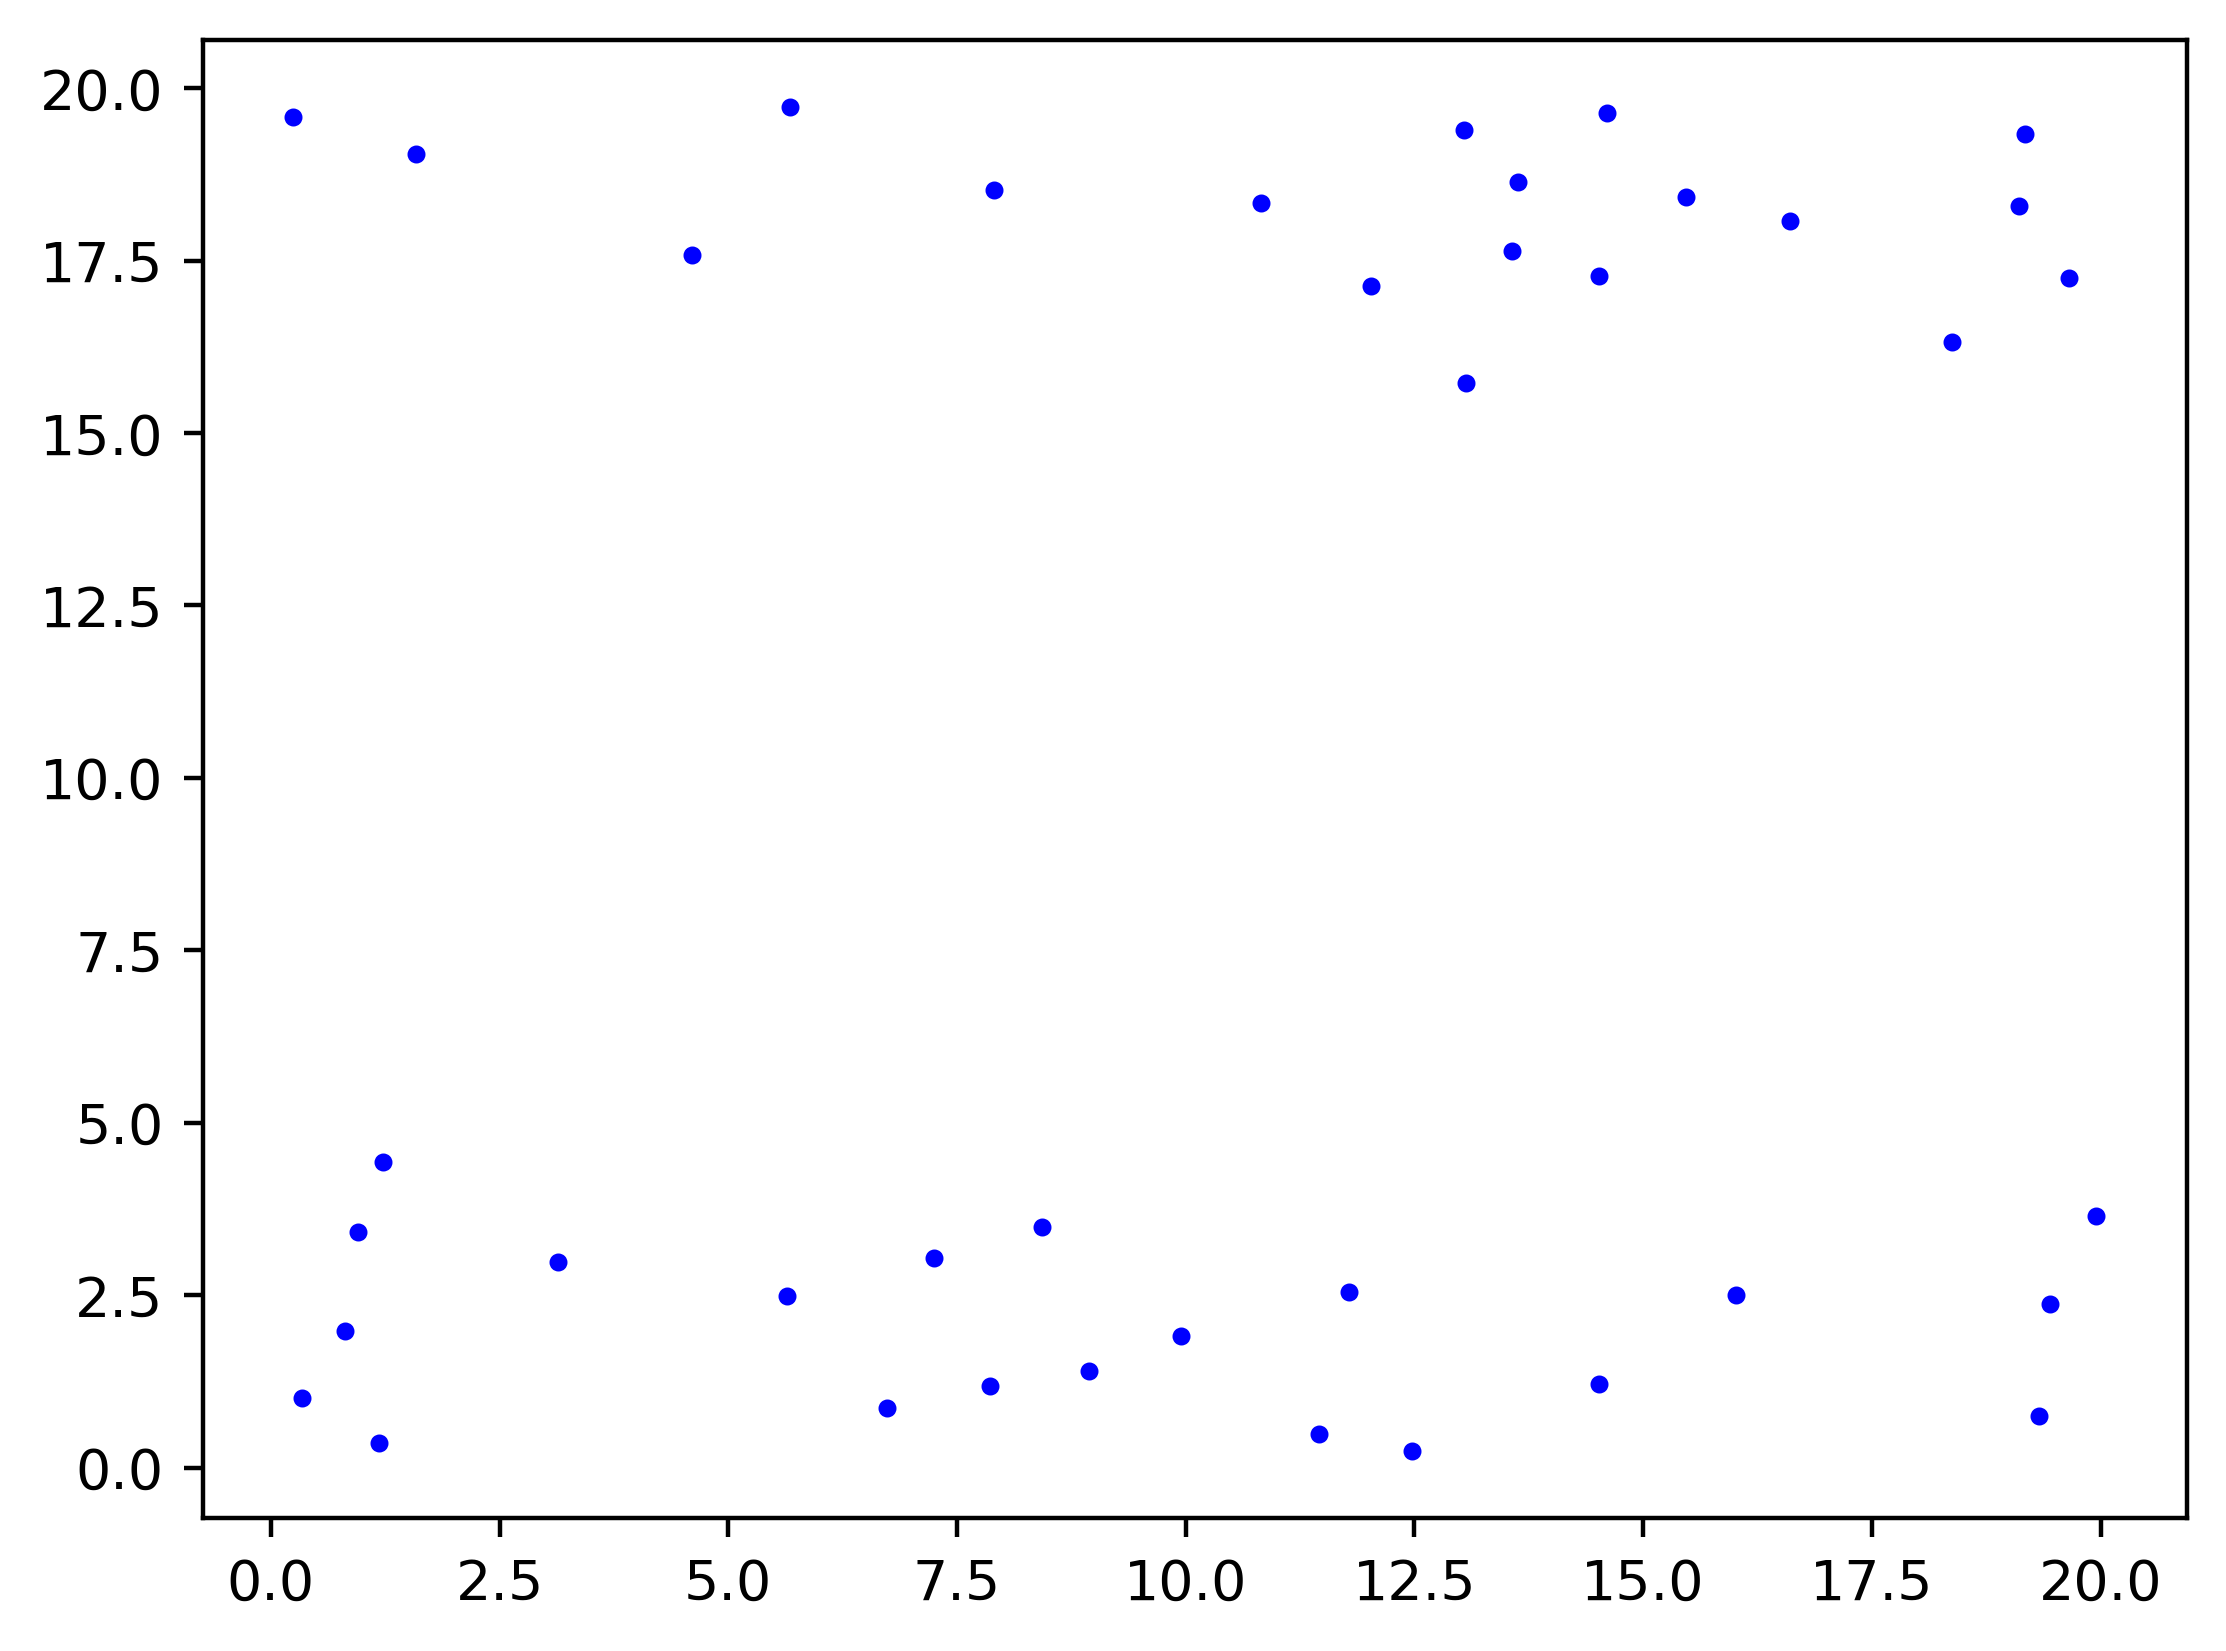

In [20]:
import torch
import numpy as np
from matplotlib import pyplot as plt
N = 40
Dt = 1.0; Dr = 3*Dt; v = 10; π = np.pi
ρ  = 0.1; L = np.sqrt(N/ρ)+0.00001

def Plot(N,n_hid,n_block,lmbda):
    Checkpoint = torch.load("data/Equivariant_MODEL_N={0}_H={1}_B={2}_λ={3}.pt".format(N,n_hid,n_block,lmbda))
    state = Checkpoint['Position']
    x = state[70,:N]%L; y = state[70,N:]%L
    plt.figure(dpi=400)
    plt.scatter(x.numpy(),y.numpy(),c='blue',s=5)

Plot(40,25,4,-0.015)


In [ ]:
def PlotVec(r):
    markersize = 50000/np.pi/L**2 * 4
    ax = plt.subplot(aspect=1)
    plt.plot([L,L], [0,2*L], '--', c='y')
    plt.plot([0,2*L], [L,L], '--', c='y')

    plt.scatter()

### 